# Chapter 30 | Worked solutions

*Decisions and Embodied Action*

These solutions connect a reward log to action choices and then to the consequences of executing those choices. The same return-conditioned table reaches the goal on the original grid and hits the moved trap on the shifted grid. A requested score does not determine an outcome.

Exercises 1-4 develop the representations by hand; 5-8 run the canonical Python routines; 9-11 give sample evaluation designs. The counts and grid are teaching examples, not trained Transformer or robot benchmark results. The last timing calculation is an idealized schedule, not a measured robot speed.

## Setup

Open this notebook inside a copy of `transformers-book`, install the repository requirements, and run all cells in order on CPU. NumPy performs the checks; Matplotlib draws three figures. The written PDF contains all eleven explanations and the same figures; this notebook and its PDF also include code and saved results.

In [1]:
from pathlib import Path
import sys

import numpy as np

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    model_path = (
        repo_root / "examples" / "ch30_decisions"
    )
    if model_path.is_dir():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError(
        "Open this notebook inside transformers-book."
    )

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
plt.rcdefaults()
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":10,
                     "axes.spines.top":False, "axes.spines.right":False})
from examples.ch30_decisions.model import returns_to_go

## 1. Compute returns-to-go

Work backward from the last reward. With $G_4=0$, the four sums are

$$G_3=4,\quad G_2=-1+4=3,\quad G_1=2+3=5,\quad G_0=0+5=5.$$

The chronological answer is $(5,5,3,4)$. At step 2 the current return includes a penalty of $-1$. Once paid, the remaining return increases: $G_3=G_2-r_2=3-(-1)=4$. Reward $r_t$ belongs to the action at step $t$, not the action before it. These are realized returns computed from a complete recorded episode.

In [3]:
rewards = np.array([0, 2, -1, 4])
manual_returns = np.array([5, 5, 3, 4])
assert manual_returns[0] == rewards.sum()
np.testing.assert_array_equal(
    np.append(manual_returns[1:], 0), manual_returns - rewards)
print("Rewards:", rewards.tolist())
print("Returns-to-go:", manual_returns.tolist())
print("After the penalty:", manual_returns[2] - rewards[2])

Rewards: [0, 2, -1, 4]
Returns-to-go: [5, 5, 3, 4]
After the penalty: 4


## 2. Identify the available tokens

The full record begins $G_0,s_0,a_0,G_1,s_1,a_1,G_2,s_2,a_2$. For the prediction at $s_2$, a two-step input window keeps steps 1 and 2. It can read $G_1,s_1,a_1,G_2,s_2$. Step 0 has been removed, and $a_2$ is causally blocked.

| Step | Tokens | Available at $s_2$ |
| --- | --- | --- |
| 0 | $G_0,s_0,a_0$ | None: outside the input window |
| 1 | $G_1,s_1,a_1$ | All three |
| 2 | $G_2,s_2,a_2$ | $G_2,s_2$ only |

The recorded $a_1$ describes an earlier decision. The recorded $a_2$ is the target being predicted; allowing it into its own context would leak the answer. In deployment, the history contains previously executed actions.

During training, $G_0$ is computed from recorded future rewards (5 in Exercise 1). During deployment, the initial return token is a supplied request $\widehat G_0$. Its later values subtract observed rewards. It cannot be filled with the realized future return of the test episode.

The figure shows three separately cropped input windows, each containing at most two steps. A full sequence with only a local per-layer mask can transmit older information across multiple layers; that is not the same construction.

At s2: ['G1', 's1', 'a1', 'G2', 's2']


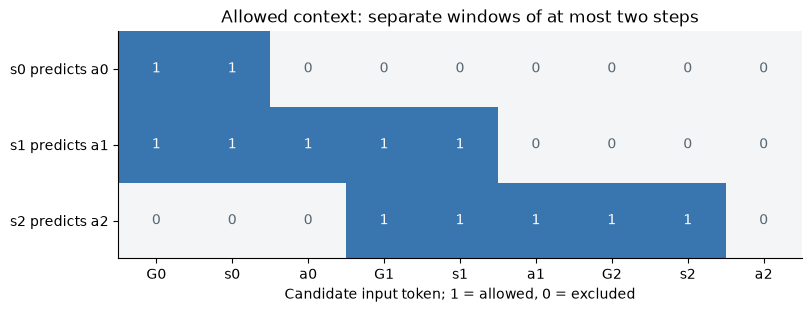

In [4]:
tokens = [f"{kind}{t}" for t in range(3) for kind in ("G","s","a")]
mask = np.zeros((3, 9), dtype=int)
for t in range(3):
    mask[t, 3*max(0, t-1):3*t+2] = 1
assert [x for x, allowed in zip(tokens, mask[2]) if allowed] == [
    "G1", "s1", "a1", "G2", "s2"]
fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
ax.imshow(mask, cmap=ListedColormap(["#f3f5f7", "#3976af"]))
ax.set_xticks(range(9), tokens)
ax.set_yticks(range(3), ["s0 predicts a0","s1 predicts a1","s2 predicts a2"])
for i in range(3):
    for j in range(9):
        ax.text(j,i,str(mask[i,j]),ha="center",va="center",
                color="white" if mask[i,j] else "#596772")
ax.set_title("Allowed context: separate windows of at most two steps")
ax.set_xlabel("Candidate input token; 1 = allowed, 0 = excluded")
plt.show()
print("At s2:", [x for x,a in zip(tokens,mask[2]) if a])

## 3. Count the two policies

At the start, three failed episodes vote for right and one successful episode votes for down. The state-only fit pools all four votes and selects right. The fit conditioned on return +1 sees only the successful episode and selects down. Conditioning on -1 selects the three failed episodes and right.

| Fit at the start | Up | Right | Down | Left | Choice |
| --- | --- | --- | --- | --- | --- |
| State only | 0 | 3 | 1 | 0 | Right |
| Return +1 | 0 | 0 | 1 | 0 | Down |
| Return -1 | 0 | 3 | 0 | 0 | Right |

Both tables use the same log. The change is which records contribute to each lookup, not a new interaction with the environment.

In [5]:
from collections import Counter
from examples.ch30_decisions.model import START, fit_count_policies, rollout
from examples.ch30_decisions.run_examples import TRAJECTORIES
state_policy, return_policy = fit_count_policies(TRAJECTORIES)
counts = Counter(action for episode in TRAJECTORIES
                 for state, action, reward in episode if state == START)
assert counts == {"R":3, "D":1}
assert state_policy[START] == "R"
assert return_policy[START,1] == "D"
assert return_policy[START,-1] == "R"
print("Start counts:", dict(counts))
print("Choices: state-only R; return +1 D; return -1 R")

Start counts: {'R': 3, 'D': 1}
Choices: state-only R; return +1 D; return -1 R


## 4. Read an action bin

Zero-based bin 1 means -1 cm; bin 4 means +2 cm. If the controller reverses the ordered table, it decodes bin 1 as +1 cm instead. A syntactically valid token can therefore move in the wrong direction.

The interface must also specify the reference frame, units, and execution interval. A displacement is not a velocity: interpreting +1 cm as +1 cm/s would change the motion. The five values here are a teaching table, not RT-2's actual discretization.

In [6]:
displacements_cm = np.array([-2, -1, 0, 1, 2])
assert displacements_cm[1] == -1 and displacements_cm[4] == 2
print("Bins 1 and 4:", displacements_cm[[1,4]].tolist(), "cm")
print("Bin 1 with reversed ordering:", displacements_cm[::-1][1], "cm")

Bins 1 and 4: [-1, 2] cm
Bin 1 with reversed ordering: 1 cm


## 5. Check the return routine

Start at the end of the trajectory with rewards $(0,2,-1,4)$. The
last action earns $4$, so its return-to-go is $4$. One step earlier,
the action costs $1$ and the later action earns $4$, leaving $3$.
Moving back two more steps adds $2$ and then $0$. In chronological
order, the four returns are $(5,5,3,4)$.

In general, the return-to-go $G_t$ includes the reward $r_t$ from the
current action and all rewards after it. With $G_T=0$ after the final
action, the backward calculation uses $G_t=r_t+G_{t+1}$. When we read
the trajectory forward, the same rule gives $G_{t+1}=G_t-r_t$.
After the penalty at step 2, subtracting $-1$ gives
$G_3=3-(-1)=4$.

At step 0 the return includes the whole trajectory, so it equals
the sum $0+2-1+4=5$. A trajectory with just one reward of $-3$
has only one return, which also equals its total of $-3$. The code
checks both full vectors, compares their first entries with Python's
`sum`, and verifies the forward rule through the terminal zero.

In [7]:
from examples.ch30_decisions.model import returns_to_go

reward_cases = [
    ([0, 2, -1, 4], [5, 5, 3, 4]),
    ([-3], [-3]),
]
for rewards, expected_returns in reward_cases:
    returns = returns_to_go(rewards)
    total = sum(rewards)
    next_returns = np.append(returns[1:], 0)

    np.testing.assert_array_equal(returns, expected_returns)
    assert returns[0] == total
    np.testing.assert_array_equal(next_returns, returns - rewards)

    print(f"Rewards = {rewards}")
    print(f"  Returns-to-go = {returns.tolist()}")
    print(f"  First return = {returns[0]:g}, total reward = {total}")

Rewards = [0, 2, -1, 4]
  Returns-to-go = [5.0, 5.0, 3.0, 4.0]
  First return = 5, total reward = 5
Rewards = [-3]
  Returns-to-go = [-3.0]
  First return = -3, total reward = -3


An empty trajectory has no current step, so its return vector is empty; indexing its first entry is invalid. The function correctly returns an array of length zero.

For the optional discounted extension, use $\gamma=1/2$. Working backward gives $4$, then $-1+(1/2)4=1$, then $2+(1/2)1=2.5$, then $(1/2)2.5=1.25$. Thus the vector is $(1.25,2.5,1,4)$. Its first entry is not the undiscounted total 5. The forward rule is $G_{t+1}=(G_t-r_t)/\gamma$, including the final zero.

In [8]:
assert returns_to_go([]).shape == (0,)
rewards = np.array([0,2,-1,4], dtype=float)
gamma = 0.5
discounted = np.zeros(len(rewards))
running = 0.0
for t in range(len(rewards)-1, -1, -1):
    running = rewards[t] + gamma*running
    discounted[t] = running
np.testing.assert_allclose(discounted, [1.25,2.5,1,4])
np.testing.assert_allclose(np.append(discounted[1:],0),
                           (discounted-rewards)/gamma)
print("Empty return vector:", returns_to_go([]).tolist())
print("Discounted returns:", discounted.tolist())

Empty return vector: []
Discounted returns: [1.25, 2.5, 1.0, 4.0]


## 6. Test an unsupported target

The log starts every demonstration at $(0,0)$. The three failed
episodes each have a return of $-1$ there, and the successful episode
has a return of $+1$. Fitting the second table stores an action for
each observed pair of position and return-to-go. At the initial
position a request for $+2$ has no entry. With $-1$, the same table
has the action `R` for right.

Keep the original grid and run the conditioned policy with both
targets. The trace records the initial state even when the first
table lookup fails. Each action that executes adds one resulting
state and one reward.

In [9]:
from examples.ch30_decisions.model import START, fit_count_policies, rollout
from examples.ch30_decisions.run_examples import TRAJECTORIES

_, return_policy = fit_count_policies(TRAJECTORIES)
assert (START, 2) not in return_policy
assert return_policy[START, -1] == "R"

unsupported = rollout(return_policy, target_return=2)
assert unsupported == {
    "states": [(0, 0)],
    "actions": [],
    "rewards": [],
    "remaining_targets": [2],
    "total_reward": 0,
    "stop_reason": "unsupported",
}

hit_trap = rollout(return_policy, target_return=-1)
assert hit_trap == {
    "states": [(0, 0), (0, 1)],
    "actions": ["R"],
    "rewards": [-1],
    "remaining_targets": [-1, 0],
    "total_reward": -1,
    "stop_reason": "trap",
}

fields = ("stop_reason", "states", "actions", "rewards", "total_reward")
for target, trace in [(2, unsupported), (-1, hit_trap)]:
    print(f"Requested return = {target:+d}")
    for field in fields:
        print(f"  {field} = {trace[field]}")

Requested return = +2
  stop_reason = unsupported
  states = [(0, 0)]
  actions = []
  rewards = []
  total_reward = 0
Requested return = -1
  stop_reason = trap
  states = [(0, 0), (0, 1)]
  actions = ['R']
  rewards = [-1]
  total_reward = -1


With $+2$, the policy stops with `unsupported` at the first lookup.
The visited state list contains just $(0,0)$. The action and reward
lists are empty, so the total reward is $0$. With $-1$, the policy
chooses `R`. The simulator moves to $(0,1)$, records reward $-1$,
and ends the episode with `trap`. The first stop comes from a
missing entry in the learned table. The second comes from an
executed action reaching a terminal cell.

Request 0 is unsupported too: the fitted table has no start entry with that return. Nevertheless, total reward 0 is possible under the episode time limit: an explicit policy that always moves up from the top-left cell stays against the wall. It reaches the step limit with zero reward. Request +2 is different: the environment can supply at most one terminal reward +1, so +2 is impossible. A missing lookup alone cannot distinguish these cases.

In [10]:
zero_request = rollout(return_policy, target_return=0)
wall_policy = {(START,0):"U"}
wall_run = rollout(wall_policy, target_return=0, max_steps=3)
assert zero_request["stop_reason"] == "unsupported"
assert zero_request["actions"] == []
assert wall_run["stop_reason"] == "step_limit"
assert wall_run["actions"] == ["U"]*3
assert wall_run["total_reward"] == 0
for name, trace in [("Fitted target 0",zero_request),("Wall policy",wall_run)]:
    print(name, trace["stop_reason"], trace["actions"],
          "total =", trace["total_reward"])

Fitted target 0 unsupported [] total = 0
Wall policy step_limit ['U', 'U', 'U'] total = 0


## 7. Inspect the shifted rollout

Keep the fitted policy and the starting target $+1$ fixed. The
original grid has its trap at $(0,1)$ and the shifted grid moves it
to $(1,1)$, a cell on the route to the goal. Run the chapter's example
module to see what the move changes.

The subprocess uses the notebook's Python interpreter and runs from
the repository root so Python can find the module. The JSON file
lives in a temporary directory and the parsed result stays available
as a Python dictionary.

In [11]:
import json
import subprocess
from tempfile import TemporaryDirectory

with TemporaryDirectory() as temporary_directory:
    output_path = Path(temporary_directory) / "ch30.json"
    subprocess.run(
        [
            sys.executable,
            "-m",
            "examples.ch30_decisions.run_examples",
            "--output",
            str(output_path),
        ],
        cwd=repo_root,
        check=True,
        stdout=subprocess.PIPE,
    )
    result = json.loads(output_path.read_text(encoding="utf-8"))
grid = result["grid"]

original_grid_run = grid["return_conditioned"]
shifted_grid_run = grid["shifted_return_conditioned"]

Each trace records the starting position as its first state. With
zero-based indices, `actions[i]` leaves `states[i]` and arrives at
`states[i + 1]` with reward `rewards[i]`. Print both transitions
using one-based step numbers, then compare the resulting state and
reward at each step the runs have in common.

In [12]:
assert grid["original_trap"] == [0, 1]
assert grid["shifted_trap"] == [1, 1]

for label, run in (
    ("Original grid", original_grid_run),
    ("Shifted grid", shifted_grid_run),
):
    assert run["states"][0] == [0, 0]
    assert len(run["states"]) == len(run["actions"]) + 1
    print(label)
    for index, action in enumerate(run["actions"]):
        state = tuple(run["states"][index])
        next_state = tuple(run["states"][index + 1])
        reward = run["rewards"][index]
        print(
            f"  {index + 1}. {state} --{action}--> {next_state}"
            f"  reward {reward:+d}"
        )
    print(f"  Stop at {run['stop_reason']}")
    print()

assert original_grid_run["actions"] == ["D", "R", "R", "U"]
assert shifted_grid_run["actions"] == ["D", "R"]
assert original_grid_run["stop_reason"] == "goal"
assert shifted_grid_run["stop_reason"] == "trap"

Original grid
  1. (0, 0) --D--> (1, 0)  reward +0
  2. (1, 0) --R--> (1, 1)  reward +0
  3. (1, 1) --R--> (1, 2)  reward +0
  4. (1, 2) --U--> (0, 2)  reward +1
  Stop at goal

Shifted grid
  1. (0, 0) --D--> (1, 0)  reward +0
  2. (1, 0) --R--> (1, 1)  reward -1
  Stop at trap



In [13]:
original_outcomes = zip(
    original_grid_run["states"][1:], original_grid_run["rewards"],
    strict=True,
)
shifted_outcomes = zip(
    shifted_grid_run["states"][1:], shifted_grid_run["rewards"],
    strict=True,
)
for step, (original, shifted) in enumerate(
    zip(original_outcomes, shifted_outcomes), start=1
):
    if original != shifted:
        break
else:
    raise AssertionError("Expected the rollout outcomes to differ.")

assert step == 2
assert original == ([1, 1], 0)
assert shifted == ([1, 1], -1)
assert original_grid_run["remaining_targets"] == [1, 1, 1, 1, 0]
assert shifted_grid_run["remaining_targets"] == [1, 1, 2]
print(f"First different outcome at step {step} (index {step - 1}).")

First different outcome at step 2 (index 1).


The first difference is the reward from the second action. Both
agents move right into $(1,1)$. That cell gives $0$ on the original
grid and $-1$ on the shifted grid, where entering it ends the
episode. Subtracting the reward leaves a target of $1-0=1$ on the
original grid and $1-(-1)=2$ on the shifted grid. The latter is
recorded in the trace at termination.

The policy looks up an action using the current position and the
remaining target. In both runs it starts at $((0,0),+1)$ and chooses
`D`. That move goes to $(1,0)$ and gives reward $0$ on both grids.
The next lookup is therefore $((1,0),+1)$ in both runs, so the
policy chooses `R` before receiving the reward for that move.

The reward plot ends each line when its episode ends; it does not invent later zero rewards for the stopped run. The changed layout is not an input to this policy. Both first decisions therefore receive identical keys, even though the second action now has a different consequence. More frequent observations of position alone would not reveal the relocated trap.

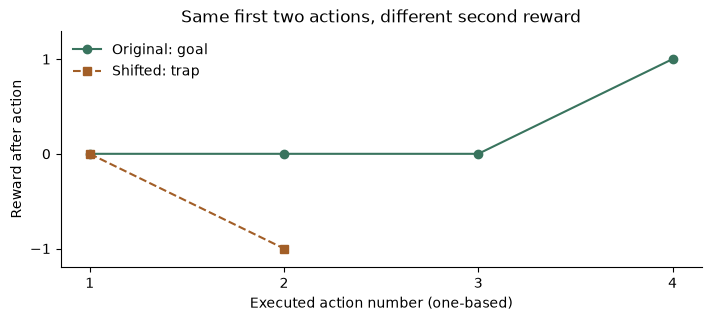

In [14]:
fig, ax = plt.subplots(figsize=(7,3.1),layout="constrained")
for label, run, style, color in [
    ("Original: goal",original_grid_run,"o-","#39745e"),
    ("Shifted: trap",shifted_grid_run,"s--","#a25e27")]:
    steps = np.arange(1,len(run["rewards"])+1)
    ax.plot(steps,run["rewards"],style,label=label,color=color)
ax.set(xticks=[1,2,3,4],yticks=[-1,0,1],ylim=(-1.2,1.3),
       xlabel="Executed action number (one-based)",ylabel="Reward after action",
       title="Same first two actions, different second reward")
ax.legend(frameon=False)
plt.show()

## 8. Vary the demonstrations

On the original grid, each trap demonstration starts with `R` and
each goal demonstration starts with `D`. The chapter's original log
has three trap demonstrations and one goal demonstration. Keep the
same two routes and reverse how often they appear. Count the logged
actions at the start and use the chapter's function to fit both
policy tables on each log.

In [15]:
from collections import Counter

from examples.ch30_decisions.model import (
    START,
    fit_count_policies,
    rollout,
)
from examples.ch30_decisions.run_examples import (
    GOAL_TRAJECTORY,
    TRAJECTORIES,
    TRAP_TRAJECTORY,
)

rebalanced_log = (TRAP_TRAJECTORY,) + (GOAL_TRAJECTORY,) * 3
original_state, original_conditioned = fit_count_policies(
    TRAJECTORIES
)
rebalanced_state, rebalanced_conditioned = fit_count_policies(
    rebalanced_log
)

print("Log          R count  D count  State-only  Conditioned (+1)")
for label, log, state_policy, conditioned_policy, expected in (
    (
        "Original", TRAJECTORIES, original_state,
        original_conditioned, {"R": 3, "D": 1},
    ),
    (
        "Rebalanced", rebalanced_log, rebalanced_state,
        rebalanced_conditioned, {"R": 1, "D": 3},
    ),
):
    start_counts = Counter(
        action
        for trajectory in log
        for state, action, _ in trajectory
        if state == START
    )
    assert start_counts == expected
    state_choice = state_policy[START]
    conditioned_choice = conditioned_policy[(START, 1)]
    print(
        f"{label:12} {start_counts['R']:7} {start_counts['D']:8}"
        f" {state_choice:^11} {conditioned_choice:^16}"
    )

assert original_state[START] == "R"
assert rebalanced_state[START] == "D"
assert original_conditioned[(START, 1)] == "D"
assert rebalanced_conditioned[(START, 1)] == "D"

Log          R count  D count  State-only  Conditioned (+1)
Original           3        1      R             D        
Rebalanced         1        3      D             D        


Now run both fitted policies on the original grid. The simulator
uses the original trap by default. For the conditioned policy,
pass `target_return=1` so that it follows the decisions recorded
with a remaining target of $+1$.

In [16]:
original_state_run = rollout(original_state)
original_target_run = rollout(original_conditioned, target_return=1)
rebalanced_state_run = rollout(rebalanced_state)
rebalanced_target_run = rollout(rebalanced_conditioned, target_return=1)

assert original_state_run["actions"] == ["R"]
assert original_state_run["stop_reason"] == "trap"
assert original_state_run["total_reward"] == -1

print("Log          Policy            Actions   Stop   Total reward")
for label, policy_name, run in (
    ("Original", "State-only", original_state_run),
    ("Original", "Conditioned (+1)", original_target_run),
    ("Rebalanced", "State-only", rebalanced_state_run),
    ("Rebalanced", "Conditioned (+1)", rebalanced_target_run),
):
    actions = " ".join(run["actions"])
    print(
        f"{label:12} {policy_name:17} {actions:9} "
        f"{run['stop_reason']:6} {run['total_reward']:+d}"
    )

for run in (
    original_target_run, rebalanced_state_run, rebalanced_target_run
):
    assert run["actions"] == ["D", "R", "R", "U"]
    assert run["states"] == [(0, 0), (1, 0), (1, 1), (1, 2), (0, 2)]
    assert run["stop_reason"] == "goal"
    assert run["total_reward"] == 1

Log          Policy            Actions   Stop   Total reward
Original     State-only        R         trap   -1
Original     Conditioned (+1)  D R R U   goal   +1
Rebalanced   State-only        D R R U   goal   +1
Rebalanced   Conditioned (+1)  D R R U   goal   +1


The state-only table pools all visits to the start. In the original
log its majority action is `R` by three votes to one, so it enters the
trap immediately. In the new log its majority action is `D` by the
same margin. At the later cells on the goal route, the log contains
only the demonstrated goal actions, so it completes `D, R, R, U`
and earns $+1$.

The conditioned table counts the two kinds of start visits under
separate keys. The `D` votes have return-to-go $+1$ and the `R` votes
have return-to-go $-1$. Repeating the goal demonstration adds votes
for the same action at each key on the goal route, so the $+1$
rollout reaches the goal with either log.

With two copies of each route, the start has two right votes and two down votes. The fixed priority is up, right, down, left; right wins this tie and the state-only rollout hits the trap. The conditioned +1 fit still has only down votes at the start and reaches the goal. Reordering the log does not change this tie rule.

In [17]:
tied_log = (TRAP_TRAJECTORY,)*2 + (GOAL_TRAJECTORY,)*2
for log in (tied_log, tied_log[::-1]):
    tied_state, tied_return = fit_count_policies(log)
    assert tied_state[START] == "R"
    assert tied_return[START,1] == "D"
    assert rollout(tied_state)["stop_reason"] == "trap"
    assert rollout(tied_return,target_return=1)["stop_reason"] == "goal"
print("Two-to-two tie: state-only R -> trap; conditioned +1 D -> goal.")

Two-to-two tie: state-only R -> trap; conditioned +1 D -> goal.


## 9. Split entire episodes

Give each trajectory an episode ID, a layout ID, and a starting condition before extracting training windows. Assign whole episodes to splits. If an episode was copied or replayed verbatim, keep its copies together. Neighboring windows may share states, actions, and return tokens computed from overlapping future rewards.

For familiar-layout generalization, reserve complete episodes beginning at selected positions within layouts represented in training. To claim a new starting position, remove other episodes starting there from training too. A position may still occur later along a training route; distinguish an unseen start from an unseen state. Separate validation starts are needed to choose settings without using the test set.

For layout generalization, withhold layout E from fitting and tuning. Train on A-D, with a separate validation group within those layouts. The observation interface must tell the learner enough about a layout if it is expected to adapt to it: equal position coordinates do not distinguish different obstacles. If feasible, rotate the held-out layout and report each result, retaining a genuine test boundary in every run.

The fact that there are 100 episodes over five layouts does not establish how many starts each layout contains. The audit below constructs 20 episode IDs per layout only to illustrate grouping. It is not a measured dataset or a guarantee that there are enough examples of each starting position.

In [18]:
episode_ids = [(layout,i) for layout in "ABCDE" for i in range(20)]
train_ids = {x for x in episode_ids if x[0] != "E" and x[1] < 16}
val_ids = {x for x in episode_ids if x[0] != "E" and x[1] >= 16}
test_ids = {x for x in episode_ids if x[0] == "E"}
assert not (train_ids & val_ids or train_ids & test_ids or val_ids & test_ids)
assert set.union(train_ids,val_ids,test_ids) == set(episode_ids)
print("Illustrative layout holdout counts:",
      len(train_ids),len(val_ids),len(test_ids))
print("Test layout:", sorted({layout for layout,_ in test_ids}))

Illustrative layout holdout counts: 64 16 20
Test layout: ['E']


## 10. Compare imitation with closed-loop success

Choose held-out starts and goals before inspecting the policies' outcomes. Use identical resets, rewards, observation and action interfaces, time budgets, and termination rules. Include ordinary starts and starts near a junction with a recoverable side route. In a stochastic simulator, pair suitable seeds and repeat independent episodes.

First run both policies without intervention and let their actions determine subsequent observations. Record goal success, total reward, executed steps, elapsed time, and stop reason. Report unsupported actions or states separately from traps and timeouts. Equal held-out action accuracy does not imply equal severity or locations of mistakes.

Run a separate recovery test with the same controlled disturbance applied to both policies: for example, force one wrong turn into a recoverable alcove, then return control to the policy. Feed it the actual resulting observation and the actually executed action history. Measure whether it returns to a valid route, actions and time to recovery, and eventual goal completion. Check that the off-route states are absent from training if the test claims recovery from unfamiliar states.

A policy can recover more often and reach more goals despite matching the same fraction of demonstration actions. Report ordinary and perturbed trials separately, with sample counts and episode-level uncertainty. Never combine them into an unspecified success denominator.

The small record below only demonstrates outcome accounting; it is supplied teaching data, not a simulator comparison. Three goals in five independent trials would be 60% observed success, with substantial uncertainty. An unsupported zero-reward trial is not a success.

In [19]:
ending_reasons = ["goal","goal","trap","unsupported","goal"]
successes = sum(reason == "goal" for reason in ending_reasons)
assert successes == 3 and len(ending_reasons) == 5
print("Illustrative endings:", dict(Counter(ending_reasons)))
print(f"Observed success: {successes}/{len(ending_reasons)} "
      f"= {successes/len(ending_reasons):.0%}")
print("This record is illustrative, not a measured policy benchmark.")

Illustrative endings: {'goal': 3, 'trap': 1, 'unsupported': 1}
Observed success: 3/5 = 60%
This record is illustrative, not a measured policy benchmark.


## 11. Evaluate the control interface

Keep the trained checkpoint, observation and instruction inputs, action decoding, controller, and prediction horizon $H=8$ fixed. Compare execution horizons $K=8$ and $K=2$. The latter executes the first two actions, discards the unused six, obtains a fresh image, and predicts another eight. Update any action history with executed commands only.

If each action lasts 0.1 s and inference takes no time, refresh intervals are $8(0.1)=0.8$ s and $2(0.1)=0.2$ s: idealized refresh rates of 1.25 and 5 Hz. Both execute actions at 10 Hz. Refresh rate and action execution rate are different quantities.

Use paired resets with the same object, pose, lighting, camera placement, instruction, and target. Include nominal trials and separate trials in which the object is displaced just after the first executed action. Align the perturbation to physical progress and use matched displacements. Define success, time and action budgets, and recovery before collecting results.

Timestamp image acquisition, inference start and end, command dispatch, and execution on one clock. Attach the source frame ID to each command. Measure observation age at execution, image-to-first-command latency, model-call count, idle waiting, completion time, goal placement, drops, and constraint violations. A command produced quickly can still use a stale queued image.

For disturbed trials, record when the shift occurred, when an observation first reflected it, when corrective movement began, whether a secure grasp or route was regained, and eventual success. Include non-recoveries, distinguishing traps or other failures from timeouts.

The figure assumes zero inference latency. With an additional 0.15 s of blocking inference at every refresh, an idealized cycle would take $0.8+0.15=0.95$ s for $K=8$ and $0.2+0.15=0.35$ s for $K=2$. Real systems may overlap computation with movement, so these are serial scheduling calculations, not universal latency formulas. More frequent high-level replanning can improve reaction opportunities while increasing waiting time or disrupting coordinated motion. Low-level sensor control may continue between image refreshes.

In [20]:
action_duration = 0.1
inference_latency = 0.15
for k in (8,2):
    execution_time = k*action_duration
    serial_cycle = execution_time + inference_latency
    print(f"K={k}: ideal refresh {execution_time:.2f} s "
          f"({1/execution_time:.2f} Hz); serial cycle {serial_cycle:.2f} s")
assert np.isclose(8*action_duration,0.8)
assert np.isclose(2*action_duration,0.2)

K=8: ideal refresh 0.80 s (1.25 Hz); serial cycle 0.95 s
K=2: ideal refresh 0.20 s (5.00 Hz); serial cycle 0.35 s


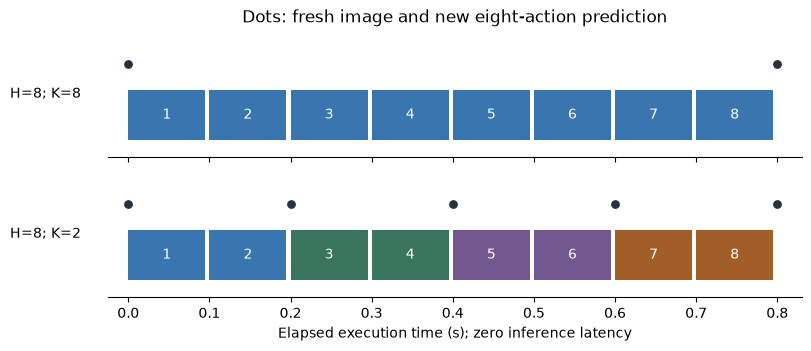

In [21]:
fig, axes = plt.subplots(2,1,figsize=(8,3.4),sharex=True,
                         layout="constrained")
colors = ["#3976af","#39745e","#72588f","#a25e27"]
for ax,k in zip(axes,(8,2)):
    for i in range(8):
        ax.add_patch(Rectangle((i*.1,.12),.095,.35,
                               facecolor=colors[(i//k)%4]))
        ax.text(i*.1+.0475,.295,str(i+1),ha="center",va="center",color="white")
    refresh = np.arange(0,9,k)*.1
    ax.scatter(refresh,np.full(len(refresh),.65),color="#26323d",s=28)
    ax.set(ylim=(0,.88),xlim=(-.025,.83),yticks=[])
    ax.set_ylabel(f"H=8; K={k}",rotation=0,labelpad=45,va="center")
    ax.spines["left"].set_visible(False)
axes[0].set_title("Dots: fresh image and new eight-action prediction")
axes[1].set_xticks(np.arange(9)*.1)
axes[1].set_xlabel("Elapsed execution time (s); zero inference latency")
plt.show()